In [1]:
# Core libraries
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from matplotlib.colors import (
    LinearSegmentedColormap,
)

# Machine-learning tools
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_score,
    learning_curve,
)
from sklearn.preprocessing import (
    LabelEncoder,
    label_binarize,
)

In [2]:
# Assemble the cluster-pair classification dataset
# from the trimmed two-AA mixture data.

# DATA_DIR = Path(".")
DATA_DIR = Path(
    "/Volumes/JAEONCHO/ADIC-AA/g_CD data"
)

TRIM_EVENT_DIR = (
    DATA_DIR / "trim_events_g_CD_mix"
)

TRIM_SUB_EVENT_DIR = (
    DATA_DIR / "trim_sub_events_g_CD_mix"
)

BASELINE_DIR = (
    DATA_DIR / "final_baseline_info_g_CD_mix"
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# Each digit identifies the cluster-specific
# single-AA classifier associated with one
# component of the mixture.
CLUSTER_PAIR_MAP = {
    "FP": 13,
    "GQ": 30,
    "LW": 20,
    "MV": 23,
    "DY": 40,
    "RV": 34,
    "HN": 10,
    "SL": 12,
    "HM": 12,
    "DP": 14,
    "SA": 10,
    "LE": 20,
    "DT": 40,
    "TV": 30,
    "MD": 24,
    "LI": 23,
    "LD": 24,
    "GH": 13,
    "VD": 34,
    "SD": 14,
}

assembled_datasets = []


for sub_event_file in sorted(
    TRIM_SUB_EVENT_DIR.glob("*.csv")
):
    recording_id = (
        sub_event_file.stem.removesuffix("_sub")
    )

    mixture_label = (
        recording_id.split("_")[0]
    )

    if mixture_label not in CLUSTER_PAIR_MAP:
        raise ValueError(
            f"No cluster-pair mapping was found for "
            f"{mixture_label}."
        )

    event_file = (
        TRIM_EVENT_DIR
        / f"{recording_id}.csv"
    )

    baseline_file = (
        BASELINE_DIR
        / f"{recording_id}_final.csv"
    )

    if not event_file.exists():
        raise FileNotFoundError(
            f"Missing trimmed event file: "
            f"{event_file.name}"
        )

    if not baseline_file.exists():
        raise FileNotFoundError(
            f"Missing baseline file: "
            f"{baseline_file.name}"
        )

    sub_events = pd.read_csv(
        sub_event_file
    )

    first_level_events = pd.read_csv(
        event_file
    )

    baseline_data = pd.read_csv(
        baseline_file
    )

    if baseline_data.empty:
        raise ValueError(
            f"Baseline file is empty: "
            f"{baseline_file.name}"
        )

    open_pore_rms = (
        baseline_data["rms"].iloc[0]
    )

    matched_rows = []

    for _, sub_event in sub_events.iterrows():
        parent_event = first_level_events.loc[
            (
                first_level_events["start_time_s"]
                <= sub_event["sub_start_time_s"]
            )
            & (
                first_level_events["end_time_s"]
                >= sub_event["sub_end_time_s"]
            )
        ]

        if parent_event.empty:
            continue

        parent_event = parent_event.iloc[0]

        event_id = (
            f"{recording_id}_"
            f"{int(parent_event['event_index'])}"
        )

        matched_rows.append({
            "sub_pre_interaction_current":
                sub_event[
                    "sub_pre_interaction_current"
                ],

            "sub_post_interaction_current":
                sub_event[
                    "sub_post_interaction_current"
                ],

            # I1
            "first_level_current":
                sub_event["sub_mode_baseline"],

            # σ1
            "first_level_stdev":
                parent_event["blockage_stdev"],

            # σ0
            "open_pore_rms":
                open_pore_rms,

            "dwell_time_us":
                parent_event["dwell_time_us"],

            # Parent first-level blockage
            "event_id":
                event_id,

            # Single-pore recording
            "dataset_id":
                recording_id,

            # Two-AA mixture identity
            "mixture_label":
                mixture_label,

            # Cluster-pair class
            "cluster_pair":
                CLUSTER_PAIR_MAP[
                    mixture_label
                ],
        })

    if matched_rows:
        assembled_datasets.append(
            pd.DataFrame(matched_rows)
        )


if not assembled_datasets:
    raise ValueError(
        "No matched mixture observations were found."
    )


df = pd.concat(
    assembled_datasets,
    ignore_index=True,
)


required_columns = [
    "sub_pre_interaction_current",
    "sub_post_interaction_current",
    "first_level_current",
    "first_level_stdev",
    "open_pore_rms",
    "dwell_time_us",
    "event_id",
    "dataset_id",
    "mixture_label",
    "cluster_pair",
]


if df[required_columns].isna().any().any():
    missing_columns = (
        df[required_columns]
        .columns[
            df[required_columns]
            .isna()
            .any()
        ]
        .tolist()
    )

    raise ValueError(
        f"Missing values detected in: "
        f"{missing_columns}"
    )


if (df["open_pore_rms"] <= 0).any():
    raise ValueError(
        "All open-pore RMS values must be positive."
    )


observed_mixtures = set(
    df["mixture_label"].unique()
)

expected_mixtures = set(
    CLUSTER_PAIR_MAP
)

if observed_mixtures != expected_mixtures:
    raise ValueError(
        "Mixture-class mismatch. "
        f"Missing: "
        f"{sorted(expected_mixtures - observed_mixtures)}; "
        f"unexpected: "
        f"{sorted(observed_mixtures - expected_mixtures)}."
    )


print(
    f"Mixture identities: "
    f"{df['mixture_label'].nunique()}"
)

print(
    f"Cluster-pair classes: "
    f"{df['cluster_pair'].nunique()}"
)

print(
    f"Secondary events: "
    f"{len(df):,}"
)

print(
    f"Parent first-level events: "
    f"{df['event_id'].nunique():,}"
)

print(
    f"Single-pore recordings: "
    f"{df['dataset_id'].nunique():,}"
)

display(
    df.head()
)

Mixture identities: 20
Cluster-pair classes: 10
Secondary events: 94,867
Parent first-level events: 7,052
Single-pore recordings: 106


,sub_pre_interaction_current,sub_post_interaction_current,first_level_current,first_level_stdev,open_pore_rms,dwell_time_us,event_id,dataset_id,mixture_label,cluster_pair
0,101.623535,120.849610,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14
1,46.081543,117.255320,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14
2,107.879640,115.173340,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14
3,106.658936,115.478516,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14
4,107.116700,117.340090,128.78418,12.573928,4.952532,12050.0,DP_g_CD_250829__0001_0,DP_g_CD_250829__0001,DP,14


In [3]:
# Encode cluster-pair labels, split by parent
# first-level blockage, and construct classifier features.

FEATURE_NAMES = [
    "Baseline Ratio",
    "Z Score",
    "Per-event Impact",
    "Per-time Impact",
]


# Encode cluster-pair labels.
cluster_label_encoder = LabelEncoder()

cluster_label_encoder.fit(
    df["cluster_pair"]
)

cluster_label_mapping = {
    int(cluster_pair): int(encoded_label)
    for cluster_pair, encoded_label
    in zip(
        cluster_label_encoder.classes_,
        cluster_label_encoder.transform(
            cluster_label_encoder.classes_
        ),
    )
}


CLUSTER_LABEL_MAPPING_PATH = (
    OUTPUT_DIR
    / "cluster_classifier_label_mapping.joblib"
)

joblib.dump(
    cluster_label_mapping,
    CLUSTER_LABEL_MAPPING_PATH,
)


print(
    "Cluster-pair label mapping:",
    cluster_label_mapping,
)


# Each event_id represents one parent
# first-level blockage.
event_table = (
    df[
        [
            "event_id",
            "dataset_id",
            "mixture_label",
            "cluster_pair",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .sort_values(
        [
            "cluster_pair",
            "event_id",
        ]
    )
    .reset_index(drop=True)
)


# Confirm that every first-level event belongs
# to one recording, mixture, and cluster pair.
event_validation = (
    df.groupby("event_id")
    .agg(
        dataset_count=(
            "dataset_id",
            "nunique",
        ),
        mixture_count=(
            "mixture_label",
            "nunique",
        ),
        cluster_pair_count=(
            "cluster_pair",
            "nunique",
        ),
    )
)


if (
    (
        event_validation["dataset_count"]
        != 1
    ).any()
    or (
        event_validation["mixture_count"]
        != 1
    ).any()
    or (
        event_validation["cluster_pair_count"]
        != 1
    ).any()
):
    raise ValueError(
        "Each event_id must correspond to one recording, "
        "one mixture, and one cluster pair."
    )


# Deterministic 60:20:20 target split within
# each cluster-pair class.
rng = np.random.default_rng(42)
split_assignment = {}


for cluster_pair in sorted(
    event_table["cluster_pair"].unique()
):
    cluster_event_ids = (
        event_table.loc[
            event_table["cluster_pair"]
            == cluster_pair,
            "event_id",
        ]
        .sort_values()
        .to_numpy()
    )

    cluster_event_ids = rng.permutation(
        cluster_event_ids
    )

    number_of_events = len(
        cluster_event_ids
    )

    number_train = max(
        1,
        int(
            np.floor(
                0.60 * number_of_events
            )
        ),
    )

    number_validation = max(
        1,
        int(
            np.floor(
                0.20 * number_of_events
            )
        ),
    )

    # Leave at least one event for testing.
    if (
        number_train
        + number_validation
        >= number_of_events
    ):
        number_validation = max(
            0,
            number_of_events
            - number_train
            - 1,
        )

    train_event_ids = (
        cluster_event_ids[:number_train]
    )

    validation_event_ids = (
        cluster_event_ids[
            number_train:
            number_train
            + number_validation
        ]
    )

    test_event_ids = (
        cluster_event_ids[
            number_train
            + number_validation:
        ]
    )

    for event_id in train_event_ids:
        split_assignment[
            event_id
        ] = "train"

    for event_id in validation_event_ids:
        split_assignment[
            event_id
        ] = "validation"

    for event_id in test_event_ids:
        split_assignment[
            event_id
        ] = "test"


# Ensure that every recording contributes at least
# one event to the training set because recording-level
# aggregate features use training observations only.
for dataset_id in sorted(
    event_table["dataset_id"].unique()
):
    recording_event_ids = (
        event_table.loc[
            event_table["dataset_id"]
            == dataset_id,
            "event_id",
        ]
        .sort_values()
        .tolist()
    )

    has_training_event = any(
        split_assignment[event_id] == "train"
        for event_id in recording_event_ids
    )

    if not has_training_event:
        event_to_move = (
            recording_event_ids[0]
        )

        split_assignment[
            event_to_move
        ] = "train"


df["split"] = df["event_id"].map(
    split_assignment
)


if df["split"].isna().any():
    raise ValueError(
        "Some observations were not assigned "
        "to a split."
    )


train_mask = (
    df["split"] == "train"
)

validation_mask = (
    df["split"] == "validation"
)

test_mask = (
    df["split"] == "test"
)


# Calculate recording-level aggregate values
# using training observations only.
training_rows = df.loc[
    train_mask
].copy()


training_event_count = (
    training_rows
    .groupby("dataset_id")
    .size()
    .rename(
        "training_secondary_event_count"
    )
)


training_dwell_time = (
    training_rows[
        [
            "dataset_id",
            "event_id",
            "dwell_time_us",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .groupby("dataset_id")[
        "dwell_time_us"
    ]
    .sum()
    .rename(
        "training_first_level_dwell_time"
    )
)


training_aggregates = pd.concat(
    [
        training_event_count,
        training_dwell_time,
    ],
    axis=1,
)


training_aggregates[
    "training_event_frequency"
] = (
    training_aggregates[
        "training_secondary_event_count"
    ]
    / training_aggregates[
        "training_first_level_dwell_time"
    ]
)


if (
    training_aggregates.isna().any().any()
    or (
        training_aggregates[
            "training_secondary_event_count"
        ]
        <= 0
    ).any()
    or (
        training_aggregates[
            "training_first_level_dwell_time"
        ]
        <= 0
    ).any()
    or (
        training_aggregates[
            "training_event_frequency"
        ]
        <= 0
    ).any()
):
    raise ValueError(
        "Invalid training-derived aggregate values."
    )


# Apply the training-derived aggregate values
# unchanged to all three splits.
feature_source = df.copy()


feature_source[
    "training_secondary_event_count"
] = feature_source["dataset_id"].map(
    training_aggregates[
        "training_secondary_event_count"
    ]
)


feature_source[
    "training_first_level_dwell_time"
] = feature_source["dataset_id"].map(
    training_aggregates[
        "training_first_level_dwell_time"
    ]
)


feature_source[
    "training_event_frequency"
] = feature_source["dataset_id"].map(
    training_aggregates[
        "training_event_frequency"
    ]
)


aggregate_columns = [
    "training_secondary_event_count",
    "training_first_level_dwell_time",
    "training_event_frequency",
]


if (
    feature_source[
        aggregate_columns
    ]
    .isna()
    .any()
    .any()
):
    missing_recordings = (
        feature_source.loc[
            feature_source[
                aggregate_columns
            ]
            .isna()
            .any(axis=1),
            "dataset_id",
        ]
        .unique()
        .tolist()
    )

    raise ValueError(
        "No training-derived aggregate values for: "
        f"{missing_recordings}"
    )


# Construct the four classifier features.
feature_source["Baseline Ratio"] = (
    feature_source[
        "sub_post_interaction_current"
    ]
    / feature_source[
        "first_level_current"
    ]
)


feature_source["Z Score"] = (
    (
        feature_source[
            "sub_post_interaction_current"
        ]
        - feature_source[
            "first_level_current"
        ]
    )
    / feature_source[
        "open_pore_rms"
    ]
)


feature_source["Per-event Impact"] = (
    feature_source["Z Score"] ** 2
    / feature_source[
        "training_secondary_event_count"
    ]
)


feature_source["Per-time Impact"] = (
    feature_source["Z Score"] ** 2
    / feature_source[
        "training_event_frequency"
    ]
)


feature_values = (
    feature_source[
        FEATURE_NAMES
    ]
    .to_numpy()
)


if not np.isfinite(feature_values).all():
    raise ValueError(
        "Nonfinite values detected in "
        "classifier features."
    )


# Create the final feature matrices.
X_train = (
    feature_source.loc[
        train_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)


X_val = (
    feature_source.loc[
        validation_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)


X_test = (
    feature_source.loc[
        test_mask,
        FEATURE_NAMES,
    ]
    .copy()
    .reset_index(drop=True)
)


y_train = (
    cluster_label_encoder.transform(
        feature_source.loc[
            train_mask,
            "cluster_pair",
        ]
    )
)


y_val = (
    cluster_label_encoder.transform(
        feature_source.loc[
            validation_mask,
            "cluster_pair",
        ]
    )
)


y_test = (
    cluster_label_encoder.transform(
        feature_source.loc[
            test_mask,
            "cluster_pair",
        ]
    )
)


groups_train = (
    feature_source.loc[
        train_mask,
        "event_id",
    ]
    .reset_index(drop=True)
    .to_numpy()
)


# Save the exact event-level split assignment.
split_assignment_df = (
    feature_source[
        [
            "event_id",
            "dataset_id",
            "mixture_label",
            "cluster_pair",
            "split",
        ]
    ]
    .drop_duplicates(subset="event_id")
    .sort_values(
        [
            "cluster_pair",
            "event_id",
        ]
    )
    .reset_index(drop=True)
)


split_assignment_df.to_csv(
    OUTPUT_DIR
    / "cluster_classifier_split_assignment.csv",
    index=False,
)


print(
    f"Training observations: "
    f"{len(X_train):,}"
)

print(
    f"Validation observations: "
    f"{len(X_val):,}"
)

print(
    f"Test observations: "
    f"{len(X_test):,}"
)

print(
    f"Label mapping saved to: "
    f"{CLUSTER_LABEL_MAPPING_PATH.resolve()}"
)

Cluster-pair label mapping: {10: 0, 12: 1, 13: 2, 14: 3, 20: 4, 23: 5, 24: 6, 30: 7, 34: 8, 40: 9}
Training observations: 57,337
Validation observations: 17,906
Test observations: 19,624
Label mapping saved to: /Users/jaeoncho/Desktop/lab/gcd_aa/codes/jupyter/ML_gCD/outputs/cluster_classifier_label_mapping.joblib


In [4]:
# Train and save the standalone
# cluster-pair classifier.

cluster_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced_subsample",
    n_jobs=-1,
)

cluster_classifier.fit(
    X_train,
    y_train,
)


CLUSTER_MODEL_PATH = (
    OUTPUT_DIR
    / "cluster_classifier.joblib"
)

joblib.dump(
    cluster_classifier,
    CLUSTER_MODEL_PATH,
)


print(
    f"Model saved to: "
    f"{CLUSTER_MODEL_PATH.resolve()}"
)

Model saved to: /Users/jaeoncho/Desktop/lab/gcd_aa/codes/jupyter/ML_gCD/outputs/cluster_classifier.joblib


In [5]:
# Evaluate the standalone cluster-pair classifier.

grouped_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_scores = cross_val_score(
    clone(cluster_classifier),
    X_train,
    y_train,
    groups=groups_train,
    cv=grouped_cv,
    scoring="accuracy",
    n_jobs=-1,
)


y_test_pred = (
    cluster_classifier.predict(
        X_test
    )
)

y_test_proba = (
    cluster_classifier.predict_proba(
        X_test
    )
)


training_accuracy = (
    cluster_classifier.score(
        X_train,
        y_train,
    )
)

validation_accuracy = (
    cluster_classifier.score(
        X_val,
        y_val,
    )
)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred,
)

f1_micro = f1_score(
    y_test,
    y_test_pred,
    average="micro",
)

f1_macro = f1_score(
    y_test,
    y_test_pred,
    average="macro",
)

precision_micro = precision_score(
    y_test,
    y_test_pred,
    average="micro",
    zero_division=0,
)

recall_micro = recall_score(
    y_test,
    y_test_pred,
    average="micro",
    zero_division=0,
)

auc_macro = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="macro",
)

auc_micro = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="micro",
)


metrics_summary = pd.DataFrame({
    "metric": [
        "training_accuracy",
        "validation_accuracy",
        "test_accuracy",
        "cross_validation_mean",
        "cross_validation_std",
        "f1_micro",
        "f1_macro",
        "precision_micro",
        "recall_micro",
        "auc_macro",
        "auc_micro",
    ],
    "value": [
        training_accuracy,
        validation_accuracy,
        test_accuracy,
        cv_scores.mean(),
        cv_scores.std(),
        f1_micro,
        f1_macro,
        precision_micro,
        recall_micro,
        auc_macro,
        auc_micro,
    ],
})


cv_results = pd.DataFrame({
    "fold": np.arange(
        1,
        len(cv_scores) + 1,
    ),
    "accuracy": cv_scores,
})


prediction_results = pd.DataFrame({
    "true_cluster_pair": (
        cluster_label_encoder.inverse_transform(
            y_test
        )
    ),
    "predicted_cluster_pair": (
        cluster_label_encoder.inverse_transform(
            y_test_pred
        )
    ),
})


metrics_summary.to_csv(
    OUTPUT_DIR
    / "cluster_classifier_metrics.csv",
    index=False,
)

cv_results.to_csv(
    OUTPUT_DIR
    / "cluster_classifier_cross_validation.csv",
    index=False,
)

prediction_results.to_csv(
    OUTPUT_DIR
    / "cluster_classifier_test_predictions.csv",
    index=False,
)


display(
    metrics_summary
)

display(
    cv_results
)

,metric,value
0,training_accuracy,0.999878
1,validation_accuracy,0.974031
2,test_accuracy,0.945016
3,cross_validation_mean,0.955385
4,cross_validation_std,0.004113
5,f1_micro,0.945016
6,f1_macro,0.952495
7,precision_micro,0.945016
8,recall_micro,0.945016
9,auc_macro,0.997197


,fold,accuracy
0,1,0.948875
1,2,0.955813
2,3,0.960000
3,4,0.952986
4,5,0.959254


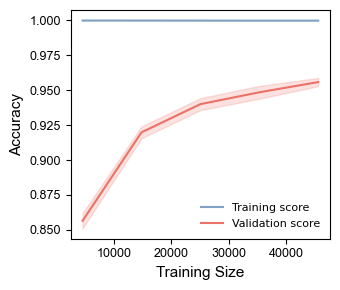

In [6]:
# Plot the grouped learning curve.

train_sizes, train_scores, validation_scores = (
    learning_curve(
        estimator=clone(cluster_classifier),
        X=X_train,
        y=y_train,
        groups=groups_train,
        cv=grouped_cv,
        train_sizes=np.linspace(
            0.1,
            1.0,
            5,
        ),
        scoring="accuracy",
        shuffle=True,
        random_state=42,
        n_jobs=-1,
    )
)

training_mean = train_scores.mean(axis=1)
training_std = train_scores.std(axis=1)

validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

learning_curve_data = pd.DataFrame({
    "training_size": train_sizes,
    "training_accuracy_mean": training_mean,
    "training_accuracy_std": training_std,
    "validation_accuracy_mean": validation_mean,
    "validation_accuracy_std": validation_std,
})

learning_curve_data.to_csv(
    OUTPUT_DIR
    / "cluster_classifier_learning_curve.csv",
    index=False,
)

plt.figure(figsize=(3.5, 3))

plt.plot(
    train_sizes,
    training_mean,
    color="#80A2C5",
    linewidth=1.5,
    label="Training score",
)

plt.fill_between(
    train_sizes,
    training_mean - training_std,
    training_mean + training_std,
    color="#80A2C5",
    alpha=0.20,
)

plt.plot(
    train_sizes,
    validation_mean,
    color="#EC7166",
    linewidth=1.5,
    label="Validation score",
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    color="#EC7166",
    alpha=0.20,
)

plt.xlabel(
    "Training Size",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "Accuracy",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.legend(
    fontsize=8,
    frameon=False,
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "cluster_classifier_learning_curve.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

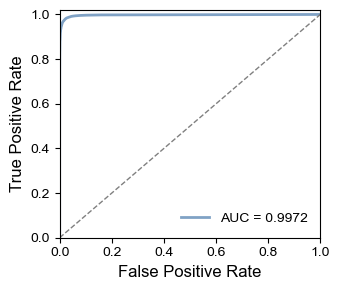

Micro-averaged ROC AUC: 0.997234
ROC curve saved to: /Users/jaeoncho/Desktop/lab/gcd_aa/codes/jupyter/ML_gCD/outputs/cluster_classifier_micro_ROC_curve.png


In [7]:
# Generate the micro-averaged ROC curve.

encoded_classes = (
    cluster_classifier.classes_
)

y_test_binary = label_binarize(
    y_test,
    classes=encoded_classes,
)


micro_fpr, micro_tpr, _ = roc_curve(
    y_test_binary.ravel(),
    y_test_proba.ravel(),
)

micro_roc_auc = auc(
    micro_fpr,
    micro_tpr,
)


roc_curve_results = pd.DataFrame({
    "false_positive_rate":
        micro_fpr,

    "true_positive_rate":
        micro_tpr,
})


roc_curve_results.to_csv(
    OUTPUT_DIR
    / "cluster_classifier_micro_ROC_curve.csv",
    index=False,
)


plt.rcParams["font.family"] = "Arial"

fig, ax = plt.subplots(
    figsize=(3.5, 3)
)


ax.plot(
    micro_fpr,
    micro_tpr,
    color="#80A2C5",
    linewidth=2,
    label=(
        f"AUC = "
        f"{micro_roc_auc:.4f}"
    ),
)

ax.plot(
    [
        0,
        1,
    ],
    [
        0,
        1,
    ],
    color="gray",
    linestyle="--",
    linewidth=1,
)


ax.set_xlim(
    0,
    1,
)

ax.set_ylim(
    0,
    1.02,
)

ax.set_xlabel(
    "False Positive Rate",
    fontsize=12,
)

ax.set_ylabel(
    "True Positive Rate",
    fontsize=12,
)

ax.tick_params(
    axis="both",
    labelsize=10,
)

ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=10,
)

fig.tight_layout()


ROC_CURVE_PATH = (
    OUTPUT_DIR
    / "cluster_classifier_micro_ROC_curve.png"
)

fig.savefig(
    ROC_CURVE_PATH,
    dpi=600,
    bbox_inches="tight",
)

plt.show()


print(
    f"Micro-averaged ROC AUC: "
    f"{micro_roc_auc:.6f}"
)

print(
    f"ROC curve saved to: "
    f"{ROC_CURVE_PATH.resolve()}"
)

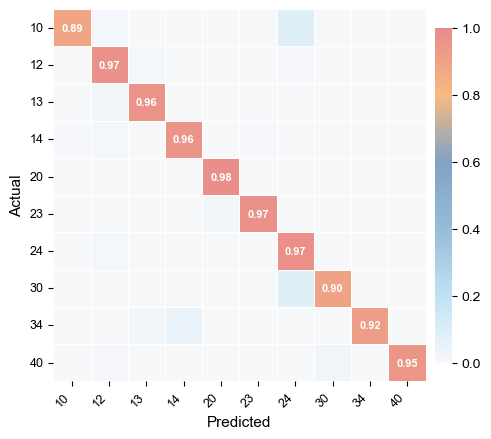

In [8]:
# Plot the normalized cluster-pair confusion matrix.

from matplotlib.colors import LinearSegmentedColormap

class_order = list(
    cluster_label_encoder.classes_
)

class_order_encoded = (
    cluster_label_encoder.transform(
        class_order
    )
)

confusion_mtx = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_order_encoded,
)

# Normalize each actual class by its row total.
confusion_mtx_normalized = np.divide(
    confusion_mtx.astype(float),
    confusion_mtx.sum(
        axis=1,
        keepdims=True,
    ),
    out=np.zeros_like(
        confusion_mtx,
        dtype=float,
    ),
    where=(
        confusion_mtx.sum(
            axis=1,
            keepdims=True,
        )
        != 0
    ),
)

confusion_matrix_data = pd.DataFrame(
    confusion_mtx_normalized,
    index=class_order,
    columns=class_order,
)

confusion_matrix_data.to_csv(
    OUTPUT_DIR
    / "cluster_classifier_confusion_matrix.csv"
)

paper_warm = (
    LinearSegmentedColormap.from_list(
        "paper_warm",
        [
            "#F7F8FA",
            "#BFE2F4",
            "#96BCD8",
            "#80A2C5",
            "#F7BB81",
            "#E88A8A",
        ],
        N=256,
    )
)

# Display values only on the diagonal.
annotations = np.full(
    confusion_mtx_normalized.shape,
    "",
    dtype=object,
)

for index in range(
    len(class_order)
):
    annotations[index, index] = (
        f"{confusion_mtx_normalized[index, index]:.2f}"
    )

plt.figure(figsize=(5.5, 4.5))

ax = sns.heatmap(
    confusion_mtx_normalized,
    annot=annotations,
    fmt="",
    cmap=paper_warm,
    vmin=0,
    vmax=1,
    xticklabels=class_order,
    yticklabels=class_order,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar=True,
    annot_kws={
        "size": 8,
        "weight": "bold",
        "color": "white",
    },
    cbar_kws={
        "shrink": 0.9,
        "pad": 0.02,
    },
)

plt.xlabel(
    "Predicted",
    fontsize=11,
    fontfamily="Arial",
)

plt.ylabel(
    "Actual",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    rotation=0,
    fontsize=9,
    fontfamily="Arial",
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "cluster_classifier_confusion_matrix.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

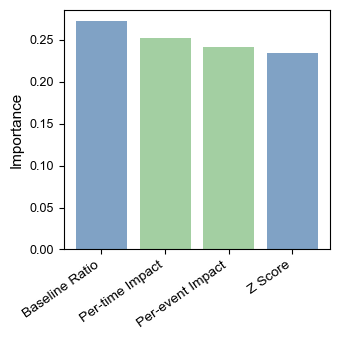

In [9]:
# Plot feature importance for the cluster classifier.

feature_importance_data = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Importance": cluster_classifier.feature_importances_,
})

feature_category = {
    "Baseline Ratio": "Local",
    "Z Score": "Local",
    "Per-event Impact": "Global",
    "Per-time Impact": "Global",
}

feature_importance_data["Category"] = (
    feature_importance_data["Feature"]
    .map(feature_category)
)

# Sort features from highest to lowest importance.
feature_importance_data = (
    feature_importance_data
    .sort_values(
        "Importance",
        ascending=False,
    )
    .reset_index(drop=True)
)

feature_importance_data.to_csv(
    OUTPUT_DIR
    / "cluster_classifier_feature_importance.csv",
    index=False,
)

# Colors retained from the existing classifier figures.
LOCAL_COLOR = "#80A2C5"
GLOBAL_COLOR = "#A3CFA2"

bar_colors = (
    feature_importance_data["Category"]
    .map({
        "Local": LOCAL_COLOR,
        "Global": GLOBAL_COLOR,
    })
    .tolist()
)

plt.figure(figsize=(3.5, 3.5))

plt.bar(
    feature_importance_data["Feature"],
    feature_importance_data["Importance"],
    color=bar_colors,
    edgecolor="none",
)

plt.xlabel("")

plt.ylabel(
    "Importance",
    fontsize=11,
    fontfamily="Arial",
)

plt.xticks(
    rotation=35,
    ha="right",
    fontsize=10,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

ax = plt.gca()
ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "cluster_classifier_feature_importance.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()